In [1]:
import pandas as pd
import numpy as np

In [2]:
df1 = pd.read_excel('parlement-elections-2011-1-0.xlsx')
df2 = pd.read_excel('parlement-elections-2016-1-1.xlsx')
df3 = pd.read_excel('parlement-elections-2021-1-0.xlsx')

# Q1 : Quelle est l’évolution de la participation moyenne (et médiane) entre 2011, 2016 et 2021 ?

In [3]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 92 entries, 0 to 91
Data columns (total 34 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   idRegion           92 non-null     int64  
 1   idWilaya           92 non-null     int64  
 2   idPrefProv         92 non-null     int64  
 3   idSousPref         8 non-null      float64
 4   idCirconscription  92 non-null     int64  
 5   region             92 non-null     str    
 6   wilaya             92 non-null     str    
 7   prefProv           92 non-null     str    
 8   sousPref           8 non-null      str    
 9   circonscription    92 non-null     str    
 10  typeListe          92 non-null     str    
 11  nSieges            92 non-null     int64  
 12  nInscrits          92 non-null     int64  
 13  txParticipation    92 non-null     float64
 14  pctNuls            92 non-null     float64
 15  AHD                92 non-null     int64  
 16  FFD                92 non-null     int6

In [4]:
df1['ntxParticipation'] = df1['txParticipation'] *df1['nInscrits']

In [5]:
df1['ntxParticipation'].head()

0     56945.0
1     81460.0
2     92235.0
3    111629.0
4    118508.0
Name: ntxParticipation, dtype: float64

In [6]:
df2.columns

Index(['idRegion', 'idWilaya', 'idPrefProv', 'idSousPref', 'idCirconscription',
       'region', 'wilaya', 'prefProv', 'sousPref', 'circonscription',
       'typeListe', 'nSieges', 'nInscrits', 'txParticipation', 'pctNuls',
       'AHD', 'FFD', 'FGD', 'MDS', 'MP', 'NEO', 'PAM', 'PAN', 'PCS', 'PDI',
       'PDN', 'PE', 'PEDD', 'PGV', 'PI', 'PJD', 'PLJS', 'PPS', 'PRD', 'PRV',
       'PSD', 'PT', 'PUD', 'RNI', 'SAP', 'UC', 'UMD', 'USFP'],
      dtype='str')

In [7]:
list_=['AHD', 'FFD', 'FGD', 'MDS', 'MP', 'NEO', 'PAM', 'PAN', 'PCS', 'PDI',
       'PDN', 'PE', 'PEDD', 'PGV', 'PI', 'PJD', 'PLJS', 'PPS', 'PRD', 'PRV',
       'PSD', 'PT', 'PUD', 'RNI', 'SAP', 'UC', 'UMD', 'USFP']
len(list_)

28

In [8]:
df2['ntxParticipation'] = df2.iloc[:,:28:-1].sum(axis=1)

In [9]:
df2['ntxParticipation'].head()

0    32774.0
1    31348.0
2    35491.0
3    35746.0
4    46990.0
Name: ntxParticipation, dtype: float64

In [10]:
df3.columns

Index(['idRegion', 'idWilaya', 'idPrefProv', 'idSousPref', 'idCirconscription',
       'region', 'wilaya', 'prefProv', 'sousPref', 'circonscription',
       'typeListe', 'nSieges', 'nInscrits', 'txParticipation', 'invalide',
       'repPctFemmes', 'repAge34', 'repAge3544', 'repAge4554', 'repAge55',
       'repEduSans', 'repEdu1aire', 'repEdu2aire', 'repEduSup', 'AFG', 'AHD',
       'FFD', 'MDS', 'MP', 'NEO', 'PA', 'PAM', 'PAN', 'PCS', 'PDI', 'PDN',
       'PE', 'PE2', 'PEDD', 'PI', 'PJD', 'PLJS', 'PML1', 'PPS', 'PRD', 'PRV',
       'PSD', 'PSU', 'PUD', 'PVM', 'RNI', 'UC', 'UMD', 'USFP'],
      dtype='str')

In [11]:
list_=['AFG', 'AHD',
       'FFD', 'MDS', 'MP', 'NEO', 'PA', 'PAM', 'PAN', 'PCS', 'PDI', 'PDN',
       'PE', 'PE2', 'PEDD', 'PI', 'PJD', 'PLJS', 'PML1', 'PPS', 'PRD', 'PRV',
       'PSD', 'PSU', 'PUD', 'PVM', 'RNI', 'UC', 'UMD', 'USFP']
len(list_)

30

In [12]:
df3['ntxParticipation'] = df2.iloc[:,:30:-1].sum(axis=1)

In [13]:
df3['ntxParticipation'].head()

0    52385.0
1    48868.0
2    60077.0
3    59614.0
4    63765.0
Name: ntxParticipation, dtype: float64

In [14]:
pct_mean1 = df1['ntxParticipation'].mean()
pct_mean2 = df2['ntxParticipation'].mean()
pct_mean3 = df3['ntxParticipation'].mean()



In [15]:
pct_means = [pct_mean1,pct_mean2,pct_mean3]

In [16]:
print(pct_mean3)

55271.278846153844


In [17]:
import matplotlib.pyplot as plt

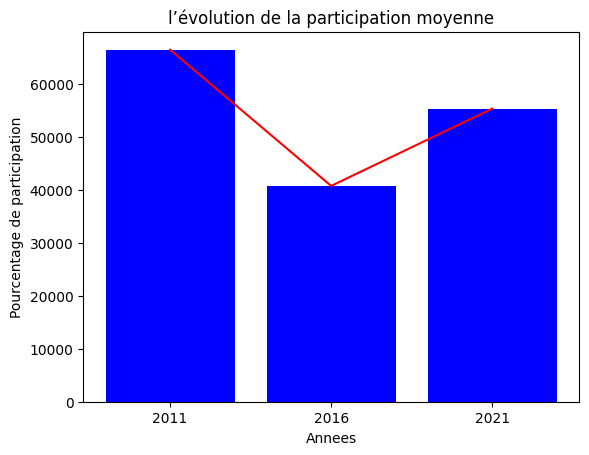

In [18]:
plt.bar(['2011','2016','2021'], pct_means,color="blue")
plt.plot(['2011','2016','2021'], pct_means,color="red")
plt.title('l’évolution de la participation moyenne')
plt.xlabel("Annees")
plt.ylabel("Pourcentage de participation")
plt.show()

# Q2: Quelles sont les 10 circonscriptions les plus mobilisées et les 10 les moins mobilisées chaque année ? Sont-elles les mêmes d’une élection à l’autre ?

In [19]:
list_trie = df1[['circonscription','ntxParticipation']].sort_values(by= ['ntxParticipation']).reset_index(drop =True)
top_10 = list_trie.tail(10)[::-1]
lower_10 = list_trie.head(10)

## ** Top 10 : **

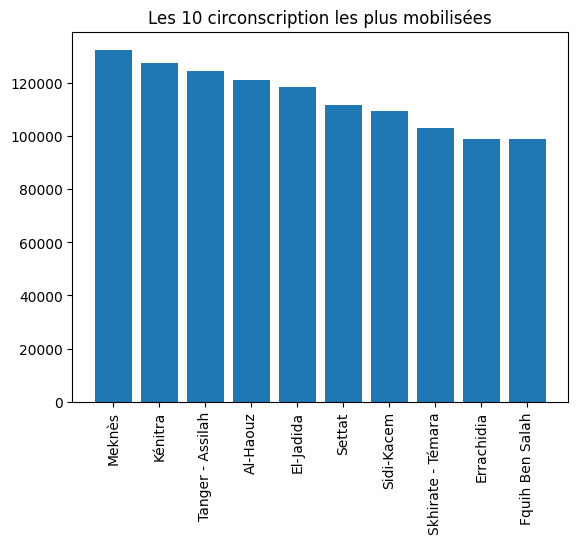

In [20]:
plt.bar(top_10['circonscription'],top_10['ntxParticipation'])
plt.title('Les 10 circonscription les plus mobilisées')
plt.xticks(rotation='vertical')
plt.show()

## ** Lower 10 : **

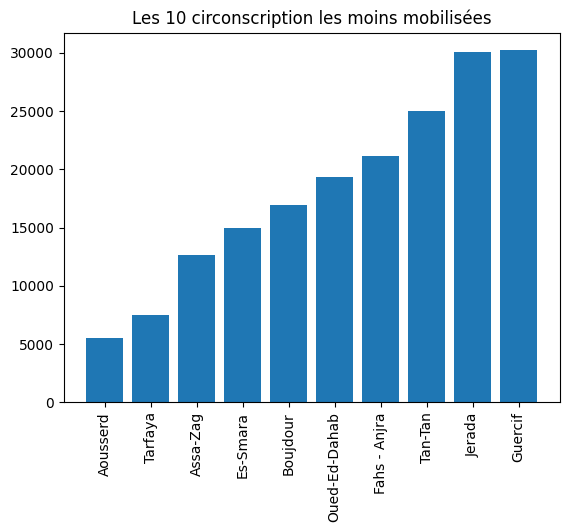

: 

In [ ]:
plt.bar(lower_10['circonscription'],lower_10['ntxParticipation'])
plt.title('Les 10 circonscription les moins mobilisées')
plt.xticks(rotation='vertical')
plt.show()